# SPSA and Layer-Wise SPSA: Optimisation and Neural Network Training without Backpropagation

**Implementation by**: Ananth Shyam, Rama Narasimha and Mahan Bhimireddy

**Paper**: B. Wulff, J. Schuecker, C. Bauckhage. *SPSA for Layer-Wise Training of Deep Networks.* ICANN 2018, LNCS 11141, pp. 564–573. [doi:10.1007/978-3-030-01424-7_55](https://doi.org/10.1007/978-3-030-01424-7_55)

### Where each requirement is covered

| Requirement | Section |
|---|---|
| Implement SPSA to optimise a sample mathematical function and show how it converges towards the minimum | **Part 1A** (2-D cubic, paper Algorithm 1) and **Part 1B** (3-factor matrix product, paper Algorithm 2) |
| Use SPSA to train a small neural network for a simple classification task, without backpropagation | **Part 2** (XOR and moons, the paper's 2×5×5×5×1 network, layer-wise SPSA) |
| Show the loss curve and compare with a conventional optimiser such as SGD or Adam | Every part compares against `torch.optim.SGD`: loss vs. iterations/epochs **and** loss vs. function evaluations, plus precision, recall, F1 and confusion matrices in Part 2 |

Every random experiment is repeated over **100 trials** and summarised by its mean or median, as in the paper's Fig. 1. The notebook runs on a CUDA GPU when one is available and otherwise on the CPU.

## 1. The two algorithms from the paper

**Algorithm 1 (SPSA, paper Sect. 2).** For $t = 1, \dots, t_{\max}$:

$$a_t = \frac{a}{t^{\alpha}}, \qquad c_t = \frac{c}{t^{\gamma}}, \qquad \delta_i \sim \mathcal{U}\{-1, +1\},$$

$$\hat g_i(x_t) = \frac{f(x_t + c_t\delta) - f(x_t - c_t\delta)}{2\,c_t\,\delta_i}, \qquad x_{t+1} = x_t - a_t\,\hat g(x_t).$$

All coordinates are perturbed **simultaneously**, so one step costs **2 function evaluations** regardless of the dimension. The paper uses $\alpha = 1$ and $\gamma \in [\tfrac16, \tfrac12]$; this notebook uses $\alpha = 1$, $\gamma = \tfrac16$ throughout.

**Algorithm 2 (layer-wise SPSA, paper Sect. 3).** In every epoch, visit the layers $l \in \mathcal{L}$ and call Algorithm 1 on the parameters of layer $l$ only, keeping all other layers fixed. The paper considers three visiting orders: bottom-up $\{1, \dots, L\}$, top-down $\{L, \dots, 1\}$ and a random permutation. Each call restarts $a_t$ and $c_t$ at $t = 1$ (paper Sect. 5: *"we reinitialize the SPSA parameters $a_t$ and $c_t$ to large values which then decrease"*).

**Holistic SPSA** is the paper's baseline: Algorithm 1 applied to all parameters at once. To give holistic and layer-wise SPSA the **same number of function evaluations**, holistic SPSA here also makes $L$ calls of $t_{\max}$ steps per epoch.

> **Coordinate-wise finite differences are not in the paper** (it mentions only the older Kiefer–Wolfowitz scheme that SPSA improves on). An earlier version of this notebook called such a method "layer-wise SPSA" on a 2-D function. That is not SPSA: with one coordinate per "layer", the $\pm 1$ in $\delta$ cancels. Here, layer-wise SPSA is only used where each "layer" has many parameters (Parts 1B and 2).

### Paper vs. this notebook

| | Paper | This notebook |
|---|---|---|
| Gains | $a_t = a/t^{\alpha}$, $c_t = c/t^{\gamma}$, restarted per SPSA call | Same, $\alpha = 1$, $\gamma = 1/6$ |
| Layer orders | bottom-up, top-down, random | All three |
| Network | 2×5×5×5×1 with biases (81 parameters), $\tanh(\beta z)$ on **all** layers, $\beta = 0.5$ | Same |
| Loss | Eq. 9: $E = \sum_i \lVert y(x_i) - y_i\rVert^2$, labels $\pm 1$ | Same |
| Data | XOR and moons (Fig. 1a, 1b), exact data not published | Regenerated: 300 points each, 200 train / 100 test |
| Trials | Training error averaged over 100 random initialisations, 25 epochs | Same |
| $a$, $c$, $t_{\max}$ for Fig. 1 | Not reported | $t_{\max} = 50$ (the paper's MNIST value); $a$, $c$ chosen by the sweep below |
| Baseline | Holistic SPSA (Fig. 1); GD on MNIST only | Holistic SPSA, plus `torch.optim.SGD` (course requirement) |
| Test metrics | Not reported for Fig. 1 | Accuracy, precision, recall, F1, confusion matrices on the held-out 100 points |
| Not included | | 3-class circles (Fig. 1c, 503 parameters) and MNIST (Fig. 2) |

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
# scikit-learn is imported before torch on purpose: on some Windows set-ups, importing it
# after torch crashes the Python process without an error message (a DLL clash).
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import torch

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
N_TRIALS = 100
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

print(f"PyTorch {torch.__version__} | NumPy {np.__version__} | device: {DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))


def print_table(title, headers, rows):
    """Prints a plain-text table with aligned columns."""
    rows = [[str(v) for v in r] for r in rows]
    widths = [max(len(h), *(len(r[i]) for r in rows)) for i, h in enumerate(headers)]
    print(title)
    print(" | ".join(h.ljust(w) for h, w in zip(headers, widths)))
    print("-+-".join("-" * w for w in widths))
    for r in rows:
        print(" | ".join(v.ljust(w) for v, w in zip(r, widths)))
    print()


def sync():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

PyTorch 2.14.0+cu126 | NumPy 2.2.6 | device: cuda (NVIDIA GeForce RTX 3050 6GB Laptop GPU)


## 2. One implementation of Algorithms 1 and 2, used by every part

`spsa_minimise` runs **many independent problems at once** (one row of `theta` per trial). This is how 100 trials run in seconds on the GPU. Each parameter carries a "layer" label (`layer_of`):

- `order="holistic"` perturbs every parameter in every step (Algorithm 1 on everything).
- `order="bottom-up" | "top-down" | "random"` perturbs only the active layer (Algorithm 2). A random order draws a new permutation per trial and per epoch.

Implementation notes:
- The objective is **logged after every update**, so `loss[0]` is the starting value and `loss[k]` is the value after update $k$.
- Every update costs exactly **2 evaluations**, $f(\theta + c_t\delta)$ and $f(\theta - c_t\delta)$. The logging evaluation is for plotting only and is not counted.
- Since $\delta_i = \pm 1$, $1/\delta_i = \delta_i$, so $\hat g = \frac{f^+ - f^-}{2c_t}\,\delta$. Parameters outside the active layer have $\delta_i = 0$ and therefore do not move.

The SGD baseline is PyTorch's own `torch.optim.SGD`. A learning-rate sweep uses one parameter group per learning rate, so all candidate rates train in one batched run.

In [2]:
def spsa_minimise(f, theta0, layer_of, order, a, c, t_max, epochs, seed,
                  epoch_callback=None, track_theta=False):
    """Paper Algorithm 1 (order='holistic') or Algorithm 2 (layer-wise orders) on a batch of problems.

    f:          maps a (B, P) tensor of parameter vectors to a (B,) tensor of objective values.
    theta0:     (S, P) starting points, one row per trial.
    layer_of:   (P,) integer tensor, the layer each parameter belongs to.
    a, c:       floats, or (S,) tensors to give every trial its own gains (used for sweeps).
    One epoch = n_layers calls of Algorithm 1, each with t_max steps and gains restarted at t = 1.
    """
    S, P = theta0.shape
    dev, dt = theta0.device, theta0.dtype
    gen = torch.Generator(device=dev).manual_seed(seed)
    n_layers = int(layer_of.max().item()) + 1
    a = torch.as_tensor(a, dtype=dt, device=dev).reshape(-1, 1).expand(S, 1)
    c = torch.as_tensor(c, dtype=dt, device=dev).reshape(-1, 1).expand(S, 1)
    all_params = torch.ones(1, P, dtype=dt, device=dev)

    theta = theta0.clone()
    loss_log, eval_log = [f(theta)], [0]
    theta_log = [theta.clone()] if track_theta else None
    epoch_metrics = [epoch_callback(theta)] if epoch_callback else []

    for epoch in range(epochs):
        if order == "random":
            perm = torch.argsort(torch.rand(S, n_layers, generator=gen, device=dev), dim=1)
        for slot in range(n_layers):
            if order == "holistic":
                mask = all_params
            else:
                if order == "bottom-up":
                    layer = torch.full((S,), slot, device=dev)
                elif order == "top-down":
                    layer = torch.full((S,), n_layers - 1 - slot, device=dev)
                elif order == "random":
                    layer = perm[:, slot]
                else:
                    raise ValueError(order)
                mask = (layer_of[None, :] == layer[:, None]).to(dt)

            for t in range(1, t_max + 1):                      # one call of Algorithm 1
                a_t, c_t = a / t, c / t ** (1.0 / 6.0)
                delta = (torch.randint(0, 2, (S, P), generator=gen, device=dev).to(dt) * 2 - 1) * mask
                f_pm = f(torch.cat([theta + c_t * delta, theta - c_t * delta]))
                f_plus, f_minus = f_pm[:S], f_pm[S:]
                g_hat = (f_plus - f_minus)[:, None] / (2 * c_t) * delta
                theta = theta - a_t * g_hat
                loss_log.append(f(theta))
                eval_log.append(eval_log[-1] + 2)
                if track_theta:
                    theta_log.append(theta.clone())
        if epoch_callback:
            epoch_metrics.append(epoch_callback(theta))

    return theta, {"loss": torch.stack(loss_log).cpu(), "evals": np.array(eval_log, dtype=float),
                   "updates_per_epoch": n_layers * t_max, "epoch_metrics": epoch_metrics,
                   "theta": torch.stack(theta_log).cpu() if track_theta else None}


def sgd_minimise(f, theta0, lrs, steps, grad_noise, seed, track_theta=False):
    """torch.optim.SGD on a deterministic function with a noisy gradient: grad f + N(0, grad_noise^2).

    lrs: list of learning rates; each gets its own copy of theta0 in its own parameter group.
    Returns rows ordered [all trials for lrs[0], all trials for lrs[1], ...].
    """
    gen = torch.Generator(device=theta0.device).manual_seed(seed)
    groups = [theta0.clone().requires_grad_(True) for _ in lrs]
    opt = torch.optim.SGD([{"params": [p], "lr": lr} for p, lr in zip(groups, lrs)], lr=lrs[0])
    with torch.no_grad():
        loss_log = [f(torch.cat(groups))]
    theta_log = [torch.cat(groups).detach().clone()] if track_theta else None
    for _ in range(steps):
        opt.zero_grad()
        f(torch.cat(groups)).sum().backward()      # problems are independent, so the sum keeps their gradients apart
        for p in groups:
            p.grad += grad_noise * torch.randn(p.shape, generator=gen, dtype=p.dtype, device=p.device)
        opt.step()
        with torch.no_grad():
            loss_log.append(f(torch.cat(groups)))
            if track_theta:
                theta_log.append(torch.cat(groups).clone())
    theta = torch.cat([p.detach() for p in groups])
    return theta, {"loss": torch.stack(loss_log).cpu(), "grad_evals": np.arange(steps + 1, dtype=float),
                   "theta": torch.stack(theta_log).cpu() if track_theta else None}

## 3. Part 1A: SPSA (Algorithm 1) on a 2-D mathematical function

$$f(x, y) = x^3 + y^3 - 3xy + 1$$

- $\nabla f = (3x^2 - 3y,\; 3y^2 - 3x)$, with critical points at $(0, 0)$ and $(1, 1)$.
- $(0, 0)$ is a **saddle** ($f = 1$, Hessian eigenvalues $\pm 3$). $(1, 1)$ is a **local minimum** ($f = 0$, eigenvalues $3$ and $9$).
- $f$ is unbounded below (take $x, y \to -\infty$), so $(1, 1)$ is a local, not a global, minimum. A method that overshoots can leave the basin and diverge, so we also count how often each method ends up at $(1, 1)$.
- Start: $(2, 0.3)$, where $f = 7.227$.

**Compared methods** (150 iterations each, 100 trials, all starting at $(2, 0.3)$):
1. **SPSA, Algorithm 1**: 2 function evaluations per iteration. Its calls of $t_{\max}$ steps restart the gains, as Algorithm 2 does.
2. **SGD (`torch.optim.SGD`)**: uses the exact autograd gradient plus Gaussian noise ($\sigma = 0.05$), the usual model of a stochastic gradient. One gradient costs about 1 forward + 1 backward pass, which we count as **3 function-evaluation equivalents**.

In [3]:
def cubic(theta):
    x, y = theta[:, 0], theta[:, 1]
    return x ** 3 + y ** 3 - 3 * x * y + 1.0

X0 = torch.tensor([2.0, 0.3], dtype=torch.float64)
X_MIN = torch.tensor([1.0, 1.0], dtype=torch.float64)
LAYER_OF_2D = torch.zeros(2, dtype=torch.long)          # one block: Algorithm 1 on both coordinates
ITERS_1A = 150

for name, pt in (("start", X0), ("saddle", torch.zeros(2, dtype=torch.float64)), ("local minimum", X_MIN)):
    p = pt.clone().requires_grad_(True)
    val = cubic(p[None])[0]
    grad = torch.autograd.grad(val, p)[0]
    hess = torch.autograd.functional.hessian(lambda q: cubic(q[None])[0], pt)
    print(f"{name:14s} {tuple(pt.tolist())}: f = {val.item():.4f}, grad = {grad.numpy().round(4)}, "
          f"Hessian eigenvalues = {torch.linalg.eigvalsh(hess).numpy().round(4)}")


def converged_1a(theta):
    """Trial ends within 0.05 of the local minimum (1, 1)."""
    ok = torch.isfinite(theta).all(dim=1)
    return ok & (torch.linalg.norm(torch.nan_to_num(theta) - X_MIN, dim=1) < 0.05)


def summarise_final(loss_final, success):
    lf = loss_final.clone()
    lf[~success] = float("nan")
    return success.double().mean().item(), torch.nanmean(lf).item(), torch.nanmedian(lf).item()

start          (2.0, 0.3): f = 7.2270, grad = [11.1  -5.73], Hessian eigenvalues = [ 0.9831 12.8169]
saddle         (0.0, 0.0): f = 1.0000, grad = [0. 0.], Hessian eigenvalues = [-3.  3.]
local minimum  (1.0, 1.0): f = 0.0000, grad = [0. 0.], Hessian eigenvalues = [3. 9.]


### 3.1 Choosing the gains and the learning rate

**Sweep set-up:**
- SPSA grid: $t_{\max} \in \{5, 10, 15, 25, 50\}$ (150 iterations = $150/t_{\max}$ calls), $a \in \{0.03, 0.05, 0.08, 0.1, 0.15\}$, $c \in \{0.02, 0.05, 0.1\}$.
- SGD grid: learning rate in $\{0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2\}$.
- The sweep uses its own random seed, separate from the final runs.

**Selection rule, the same for both methods:** keep the settings where all 100 trials converge to $(1, 1)$, then pick the lowest mean final $f$.

In [4]:
TUNE_SEED, FINAL_SEED = 1234, 0
A_1A, C_1A, TMAX_1A = [0.03, 0.05, 0.08, 0.1, 0.15], [0.02, 0.05, 0.1], [5, 10, 15, 25, 50]
LR_1A = [0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2]

spsa_rows, spsa_best = [], None
for t_max in TMAX_1A:
    configs = [(a, c) for a in A_1A for c in C_1A]
    a_vec = torch.tensor([a for a, c in configs for _ in range(N_TRIALS)], dtype=torch.float64)
    c_vec = torch.tensor([c for a, c in configs for _ in range(N_TRIALS)], dtype=torch.float64)
    theta0 = X0.repeat(len(configs) * N_TRIALS, 1)
    th, log = spsa_minimise(cubic, theta0, LAYER_OF_2D, "holistic", a_vec, c_vec, t_max, ITERS_1A // t_max, TUNE_SEED)
    fin, ok = log["loss"][-1].view(len(configs), N_TRIALS), converged_1a(th).view(len(configs), N_TRIALS)
    for k, (a, c) in enumerate(configs):
        frac, mean, med = summarise_final(fin[k], ok[k])
        spsa_rows.append((t_max, a, c, f"{100 * frac:.0f}%", f"{mean:.2e}", f"{med:.2e}"))
        if frac == 1.0 and (spsa_best is None or mean < spsa_best[0]):
            spsa_best = (mean, t_max, a, c)

theta0 = X0.repeat(N_TRIALS, 1)
th, log = sgd_minimise(cubic, theta0, LR_1A, ITERS_1A, 0.05, TUNE_SEED)
fin, ok = log["loss"][-1].view(len(LR_1A), N_TRIALS), converged_1a(th).view(len(LR_1A), N_TRIALS)
sgd_rows, sgd_best = [], None
for k, lr in enumerate(LR_1A):
    frac, mean, med = summarise_final(fin[k], ok[k])
    sgd_rows.append((lr, f"{100 * frac:.0f}%", f"{mean:.2e}", f"{med:.2e}"))
    if frac == 1.0 and (sgd_best is None or mean < sgd_best[0]):
        sgd_best = (mean, lr)

_, TMAX_A, A_A, C_A = spsa_best
LR_A = sgd_best[1]
spsa_rows = [r + ("<- chosen",) if r[:3] == (TMAX_A, A_A, C_A) else r + ("",) for r in spsa_rows]
sgd_rows = [r + ("<- chosen",) if r[0] == LR_A else r + ("",) for r in sgd_rows]
print_table("SPSA sweep (100 trials each): converged = ends within 0.05 of (1, 1)",
            ["t_max", "a", "c", "converged", "mean final f", "median final f", ""], spsa_rows)
print_table("SGD learning-rate sweep (100 trials each, gradient noise sigma = 0.05)",
            ["lr", "converged", "mean final f", "median final f", ""], sgd_rows)
print(f"Chosen: SPSA t_max = {TMAX_A}, a = {A_A}, c = {C_A} | SGD lr = {LR_A}")

SPSA sweep (100 trials each): converged = ends within 0.05 of (1, 1)
t_max | a    | c    | converged | mean final f | median final f |          
------+------+------+-----------+--------------+----------------+----------
5     | 0.03 | 0.02 | 100%      | 9.15e-07     | 7.30e-08       |          
5     | 0.03 | 0.05 | 100%      | 3.52e-06     | 1.92e-06       |          
5     | 0.03 | 0.1  | 100%      | 2.33e-05     | 2.19e-05       |          
5     | 0.05 | 0.02 | 100%      | 4.15e-08     | 3.76e-08       | <- chosen
5     | 0.05 | 0.05 | 100%      | 1.42e-06     | 1.42e-06       |          
5     | 0.05 | 0.1  | 100%      | 2.23e-05     | 2.23e-05       |          
5     | 0.08 | 0.02 | 98%       | 3.51e-08     | 3.46e-08       |          
5     | 0.08 | 0.05 | 100%      | 1.37e-06     | 1.37e-06       |          
5     | 0.08 | 0.1  | 99%       | 2.22e-05     | 2.22e-05       |          
5     | 0.1  | 0.02 | 99%       | 3.50e-08     | 3.48e-08       |          
5     | 0.1  | 0.05

### 3.2 Final runs: 100 trials each with the chosen settings

In [5]:
theta0 = X0.repeat(N_TRIALS, 1)
t0 = time.perf_counter()
th_spsa_1a, log_spsa_1a = spsa_minimise(cubic, theta0, LAYER_OF_2D, "holistic", A_A, C_A, TMAX_A,
                                        ITERS_1A // TMAX_A, FINAL_SEED, track_theta=True)
time_spsa_1a = time.perf_counter() - t0
t0 = time.perf_counter()
th_sgd_1a, log_sgd_1a = sgd_minimise(cubic, theta0, [LR_A], ITERS_1A, 0.05, FINAL_SEED, track_theta=True)
time_sgd_1a = time.perf_counter() - t0

evals_spsa_1a = log_spsa_1a["evals"]                    # 2 function evaluations per iteration
evals_sgd_1a = 3 * log_sgd_1a["grad_evals"]             # 1 gradient ~ 3 function-evaluation equivalents

rows = []
for name, th, log, ev, sec in (("SPSA (Algorithm 1)", th_spsa_1a, log_spsa_1a, evals_spsa_1a, time_spsa_1a),
                               ("SGD (torch.optim.SGD)", th_sgd_1a, log_sgd_1a, evals_sgd_1a, time_sgd_1a)):
    ok = converged_1a(th)
    frac, mean, med = summarise_final(log["loss"][-1], ok)
    med_xy = torch.nanmedian(th, dim=0).values
    rows.append((name, f"{ev[-1]:.0f}", f"{100 * frac:.0f}%", f"{mean:.2e}", f"{med:.2e}",
                 f"({med_xy[0]:.4f}, {med_xy[1]:.4f})", f"{log['loss'][-1][0]:.2e}", f"{sec:.2f}"))
print_table(f"Part 1A: final results after {ITERS_1A} iterations (100 trials)",
            ["method", "function evals", "converged", "mean final f", "median final f",
             "median final (x, y)", "trial-0 final f", "time (s)"], rows)

ck = list(range(0, ITERS_1A + 1, 15))
med_spsa, med_sgd = log_spsa_1a["loss"].median(dim=1).values, log_sgd_1a["loss"].median(dim=1).values
print_table("Part 1A: f after each 15 iterations (median over 100 trials; logged after each update)",
            ["iteration", "SPSA evals", "SPSA median f", "SGD evals", "SGD median f"],
            [(k, f"{evals_spsa_1a[k]:.0f}", f"{med_spsa[k]:.6f}", f"{evals_sgd_1a[k]:.0f}", f"{med_sgd[k]:.6f}") for k in ck])

Part 1A: final results after 150 iterations (100 trials)
method                | function evals | converged | mean final f | median final f | median final (x, y) | trial-0 final f | time (s)
----------------------+----------------+-----------+--------------+----------------+---------------------+-----------------+---------
SPSA (Algorithm 1)    | 300            | 100%      | 3.75e-08     | 3.67e-08       | (0.9999, 0.9999)    | 3.17e-08        | 0.06    
SGD (torch.optim.SGD) | 450            | 100%      | 1.32e-05     | 1.01e-05       | (0.9999, 0.9999)    | 1.60e-05        | 0.13    

Part 1A: f after each 15 iterations (median over 100 trials; logged after each update)
iteration | SPSA evals | SPSA median f | SGD evals | SGD median f
----------+------------+---------------+-----------+-------------
0         | 0          | 7.227000      | 0         | 7.227000    
15        | 30         | 0.013795      | 45        | 0.346687    
30        | 60         | 0.001645      | 90        | 0.

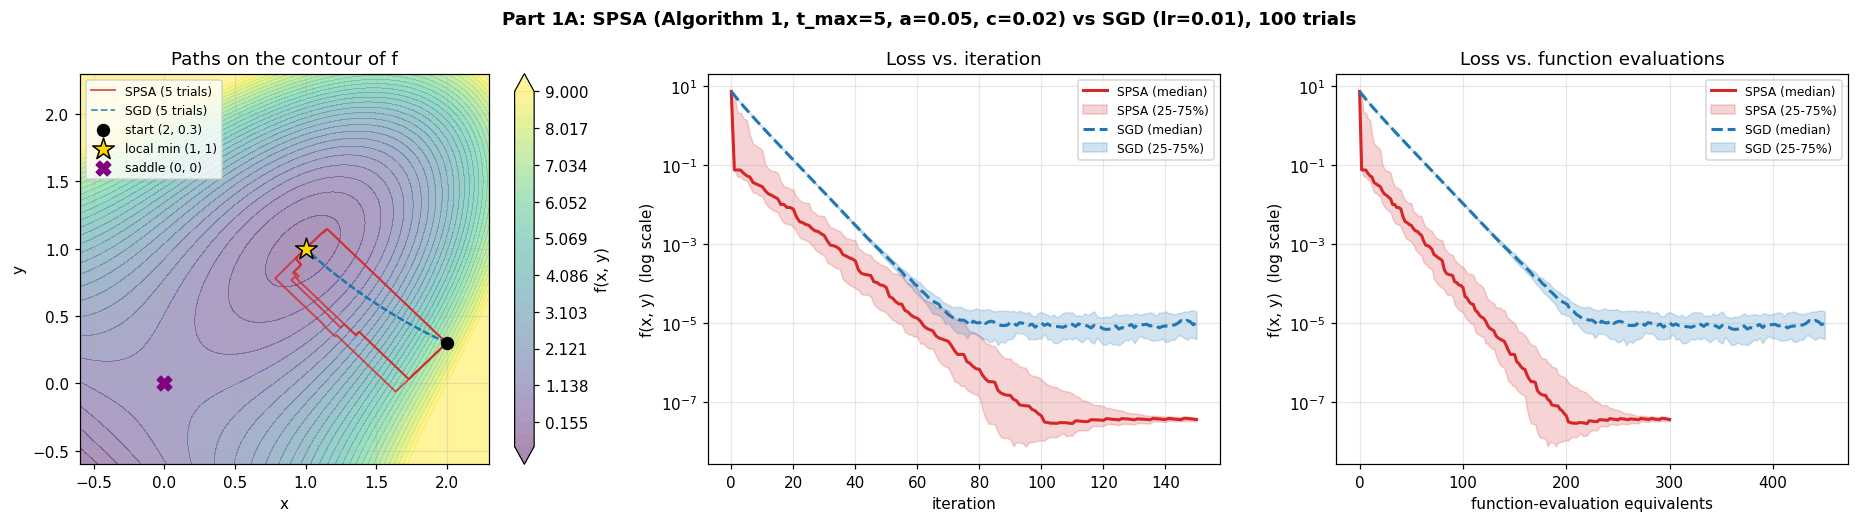

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

ax = axes[0]
gx = np.linspace(-0.6, 2.3, 300)
XX, YY = np.meshgrid(gx, gx)
ZZ = XX ** 3 + YY ** 3 - 3 * XX * YY + 1
cs = ax.contourf(XX, YY, ZZ, levels=np.linspace(-0.5, 9, 30), cmap="viridis", alpha=0.45, extend="both")
fig.colorbar(cs, ax=ax, label="f(x, y)")
for tr in range(5):
    lab = tr == 0
    ax.plot(*log_spsa_1a["theta"][:, tr].T, color="#d62728", lw=1.2, alpha=0.8, label="SPSA (5 trials)" if lab else None)
    ax.plot(*log_sgd_1a["theta"][:, tr].T, color="#1f77b4", lw=1.2, ls="--", alpha=0.8, label="SGD (5 trials)" if lab else None)
ax.scatter(*X0, c="black", s=60, zorder=5, label="start (2, 0.3)")
ax.scatter(1, 1, marker="*", c="gold", edgecolor="black", s=220, zorder=6, label="local min (1, 1)")
ax.scatter(0, 0, marker="X", c="purple", s=90, zorder=6, label="saddle (0, 0)")
ax.set(xlim=(-0.6, 2.3), ylim=(-0.6, 2.3), xlabel="x", ylabel="y", title="Paths on the contour of f")
ax.legend(fontsize=8, loc="upper left")


def band(ax, x, loss, color, label, ls="-"):
    q = np.nanquantile(loss.numpy(), [0.25, 0.5, 0.75], axis=1)
    ax.plot(x, q[1], color=color, ls=ls, lw=2, label=label + " (median)")
    ax.fill_between(x, q[0], q[2], color=color, alpha=0.2, label=label + " (25-75%)")


for ax, xs, xlabel, title in ((axes[1], (np.arange(ITERS_1A + 1), np.arange(ITERS_1A + 1)), "iteration", "Loss vs. iteration"),
                              (axes[2], (evals_spsa_1a, evals_sgd_1a), "function-evaluation equivalents", "Loss vs. function evaluations")):
    band(ax, xs[0], log_spsa_1a["loss"], "#d62728", "SPSA")
    band(ax, xs[1], log_sgd_1a["loss"], "#1f77b4", "SGD", ls="--")
    ax.set_yscale("log")
    ax.set(xlabel=xlabel, ylabel="f(x, y)  (log scale)", title=title)
    ax.legend(fontsize=8)
fig.suptitle(f"Part 1A: SPSA (Algorithm 1, t_max={TMAX_A}, a={A_A}, c={C_A}) vs SGD (lr={LR_A}), 100 trials", fontweight="bold")
plt.tight_layout()
plt.show()

## 4. Part 1B: layer-wise SPSA (Algorithm 2) on a "layered" mathematical function

Layer-wise SPSA needs a function whose parameters come in layers. The paper motivates Algorithm 2 with *"experience with hierarchical factor models [2, 26]"*, so we use the simplest such model, a product of three matrix factors:

$$f(W_1, W_2, W_3) = \lVert W_3 W_2 W_1 - M \rVert_F^2, \qquad W_l \in \mathbb{R}^{5 \times 5}.$$

- There are 75 parameters in three "layers" of 25 each, close to Part 2's 81-parameter network.
- $M$ is a fixed product of three random matrices, so the minimum value $0$ is reachable.
- Each trial starts at $W_l = I + 0.1\,\mathcal{N}(0, 1)$, with different noise per trial.
- The function is non-convex and has the same layered structure as a network, but no data.

**Settings:**
- Both SPSA variants run 20 epochs of 3 calls × $t_{\max} = 25$ steps: 1,500 updates and 3,000 function evaluations.
- SGD (`torch.optim.SGD` with gradient noise $\sigma = 0.05$) gets the same budget: 1,000 gradient steps, about 3,000 function-evaluation equivalents.

**How the gains are chosen (the paper's protocol):** first pick $(a, c)$ for layer-wise SPSA, then run holistic SPSA with **the same** $(a, c)$. As an extra check, holistic SPSA also gets its own best $(a, c)$. Tuning uses 20 separate starting points; the final results use 100 others.

In [7]:
N_MAT, N_FACT = 5, 3
_g = torch.Generator().manual_seed(0)
_factors = [torch.eye(N_MAT, dtype=torch.float64) + 0.4 * torch.randn(N_MAT, N_MAT, generator=_g, dtype=torch.float64) / N_MAT ** 0.5
            for _ in range(N_FACT)]
M_TARGET = _factors[2] @ _factors[1] @ _factors[0]
LAYER_OF_MF = torch.arange(N_FACT).repeat_interleave(N_MAT * N_MAT)
EPOCHS_1B, TMAX_1B = 20, 25
SGD_STEPS_1B = EPOCHS_1B * N_FACT * TMAX_1B * 2 // 3        # same function-evaluation budget


def factor_loss(theta):
    W = theta.reshape(-1, N_FACT, N_MAT, N_MAT)
    return ((W[:, 2] @ W[:, 1] @ W[:, 0] - M_TARGET) ** 2).sum(dim=(1, 2))


def factor_init(n, seed):
    g = torch.Generator().manual_seed(seed)
    eye = torch.eye(N_MAT, dtype=torch.float64).flatten().repeat(N_FACT)
    return eye + 0.1 * torch.randn(n, N_FACT * N_MAT * N_MAT, generator=g, dtype=torch.float64)


def finite_mean(v):
    v = torch.where(torch.isfinite(v), v, torch.full_like(v, float("inf")))
    return v.mean().item()


A_1B, C_1B, LR_1B = [0.0025, 0.005, 0.01, 0.02, 0.03], [0.02, 0.05, 0.1], [0.001, 0.002, 0.005, 0.01, 0.02, 0.05]
theta_tune = factor_init(20, seed=1000)
configs = [(a, c) for a in A_1B for c in C_1B]
a_vec = torch.tensor([a for a, c in configs for _ in range(20)], dtype=torch.float64)
c_vec = torch.tensor([c for a, c in configs for _ in range(20)], dtype=torch.float64)
sweep = {}
for order in ("holistic", "bottom-up"):
    th, log = spsa_minimise(factor_loss, theta_tune.repeat(len(configs), 1), LAYER_OF_MF, order,
                            a_vec, c_vec, TMAX_1B, EPOCHS_1B, TUNE_SEED)
    sweep[order] = log["loss"][-1].view(len(configs), 20)

best_lw = min(range(len(configs)), key=lambda k: finite_mean(sweep["bottom-up"][k]))
best_hol = min(range(len(configs)), key=lambda k: finite_mean(sweep["holistic"][k]))
A_B, C_B = configs[best_lw]
A_HB, C_HB = configs[best_hol]
rows = []
for k, (a, c) in enumerate(configs):
    tags = ("<- shared gains (best layer-wise)" if k == best_lw else "") + (" <- best holistic" if k == best_hol else "")
    rows.append((a, c,
                 f"{finite_mean(sweep['bottom-up'][k]):.2e}", f"{100 * (~torch.isfinite(sweep['bottom-up'][k])).double().mean():.0f}%",
                 f"{finite_mean(sweep['holistic'][k]):.2e}", f"{100 * (~torch.isfinite(sweep['holistic'][k])).double().mean():.0f}%", tags))
print_table("Part 1B SPSA sweep (20 tuning starts, mean final f; 'inf' = some trials diverged)",
            ["a", "c", "layer-wise mean f", "layer-wise diverged", "holistic mean f", "holistic diverged", ""], rows)

th, log = sgd_minimise(factor_loss, theta_tune, LR_1B, SGD_STEPS_1B, 0.05, TUNE_SEED)
fin = log["loss"][-1].view(len(LR_1B), 20)
best_lr = min(range(len(LR_1B)), key=lambda k: finite_mean(fin[k]))
LR_B = LR_1B[best_lr]
print_table("Part 1B SGD learning-rate sweep (20 tuning starts)", ["lr", "mean final f", ""],
            [(lr, f"{finite_mean(fin[k]):.2e}", "<- chosen" if k == best_lr else "") for k, lr in enumerate(LR_1B)])

Part 1B SPSA sweep (20 tuning starts, mean final f; 'inf' = some trials diverged)
a      | c    | layer-wise mean f | layer-wise diverged | holistic mean f | holistic diverged |                                  
-------+------+-------------------+---------------------+-----------------+-------------------+----------------------------------
0.0025 | 0.02 | 4.14e-01          | 0%                  | 2.00e-02        | 0%                |                                  
0.0025 | 0.05 | 4.15e-01          | 0%                  | 2.31e-02        | 0%                |                                  
0.0025 | 0.1  | 4.36e-01          | 0%                  | 3.53e-02        | 0%                |                                  
0.005  | 0.02 | 6.28e-02          | 0%                  | 2.41e-03        | 0%                |                                  
0.005  | 0.05 | 6.93e-02          | 0%                  | 4.08e-03        | 0%                |                                  
0.005  |

Part 1B SGD learning-rate sweep (20 tuning starts)
lr    | mean final f |          
------+--------------+----------
0.001 | 2.54e-03     |          
0.002 | 1.26e-04     |          
0.005 | 8.76e-05     | <- chosen
0.01  | 1.70e-04     |          
0.02  | 3.46e-04     |          
0.05  | 9.71e-04     |          



Initial f (mean over trials): 4.273
Part 1B: final results (100 trials; mean/median over non-diverged trials)
method                         | setting        | function evals | diverged | mean final f | median final f | time (s)
-------------------------------+----------------+----------------+----------+--------------+----------------+---------
Layer-wise SPSA (bottom-up)    | a=0.03, c=0.1  | 3000           | 0%       | 5.65e-04     | 9.11e-05       | 1.37    
Holistic SPSA (same gains)     | a=0.03, c=0.1  | 3000           | 100%     | -            | -              | 1.28    
Holistic SPSA (own best gains) | a=0.01, c=0.02 | 3000           | 0%       | 2.26e-03     | 1.89e-04       | 1.27    
SGD (torch.optim.SGD)          | lr=0.005       | 3000           | 0%       | 8.10e-05     | 7.74e-05       | 1.86    



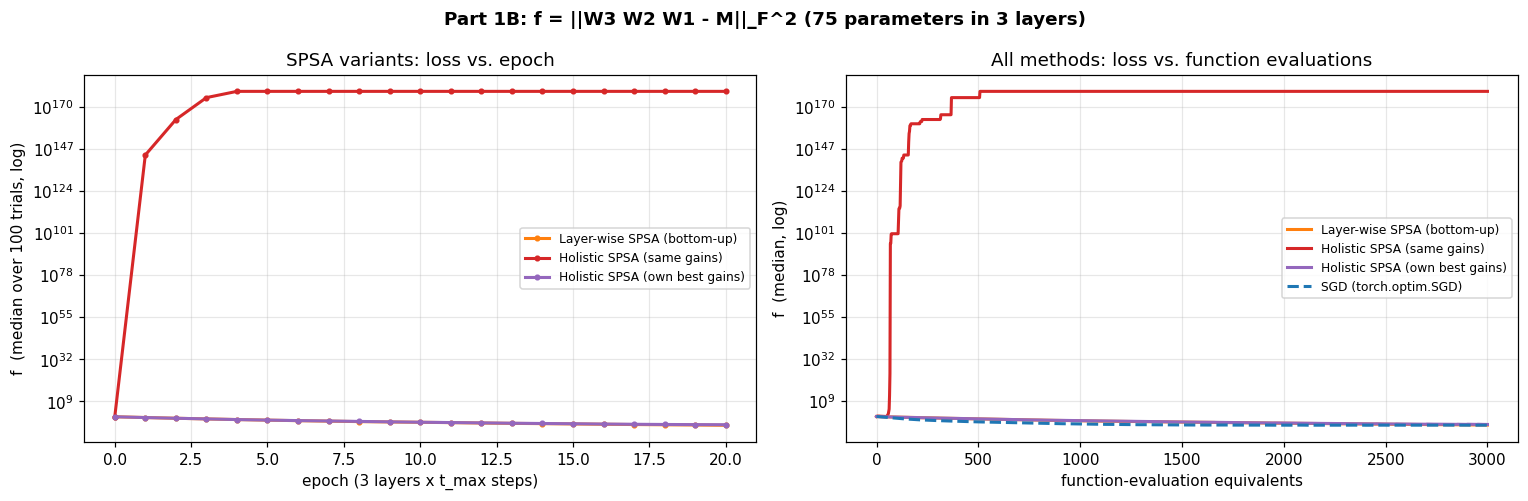

In [8]:
theta0_1b = factor_init(N_TRIALS, seed=FINAL_SEED)
runs_1b = {}
for name, order, a, c in (("Layer-wise SPSA (bottom-up)", "bottom-up", A_B, C_B),
                          ("Holistic SPSA (same gains)", "holistic", A_B, C_B),
                          ("Holistic SPSA (own best gains)", "holistic", A_HB, C_HB)):
    t0 = time.perf_counter()
    th, log = spsa_minimise(factor_loss, theta0_1b, LAYER_OF_MF, order, a, c, TMAX_1B, EPOCHS_1B, FINAL_SEED)
    runs_1b[name] = dict(loss=log["loss"], evals=log["evals"], setting=f"a={a}, c={c}", sec=time.perf_counter() - t0)
t0 = time.perf_counter()
th, log = sgd_minimise(factor_loss, theta0_1b, [LR_B], SGD_STEPS_1B, 0.05, FINAL_SEED)
runs_1b["SGD (torch.optim.SGD)"] = dict(loss=log["loss"], evals=3 * log["grad_evals"], setting=f"lr={LR_B}",
                                       sec=time.perf_counter() - t0)

rows = []
for name, r in runs_1b.items():
    fin = r["loss"][-1]
    div = ~torch.isfinite(fin) | (fin > 1e3)
    good = fin[~div]
    rows.append((name, r["setting"], f"{r['evals'][-1]:.0f}", f"{100 * div.double().mean():.0f}%",
                 f"{good.mean():.2e}" if len(good) else "-", f"{good.median():.2e}" if len(good) else "-", f"{r['sec']:.2f}"))
print(f"Initial f (mean over trials): {factor_loss(theta0_1b).mean():.3f}")
print_table("Part 1B: final results (100 trials; mean/median over non-diverged trials)",
            ["method", "setting", "function evals", "diverged", "mean final f", "median final f", "time (s)"], rows)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
colors = {"Layer-wise SPSA (bottom-up)": "#ff7f0e", "Holistic SPSA (same gains)": "#d62728",
          "Holistic SPSA (own best gains)": "#9467bd", "SGD (torch.optim.SGD)": "#1f77b4"}
upe = N_FACT * TMAX_1B
for name, r in runs_1b.items():
    loss = torch.where(torch.isfinite(r["loss"]), r["loss"], torch.full_like(r["loss"], float("nan"))).numpy()
    med = np.nanmedian(loss, axis=1)
    ls = "--" if "SGD" in name else "-"
    axes[1].plot(r["evals"], med, color=colors[name], ls=ls, lw=2, label=name)
    if "SGD" not in name:
        axes[0].plot(np.arange(EPOCHS_1B + 1), med[::upe], color=colors[name], marker="o", ms=3, lw=2, label=name)
axes[0].set(yscale="log", xlabel="epoch (3 layers x t_max steps)", ylabel="f  (median over 100 trials, log)",
            title="SPSA variants: loss vs. epoch")
axes[1].set(yscale="log", xlabel="function-evaluation equivalents", ylabel="f  (median, log)",
            title="All methods: loss vs. function evaluations")
for ax in axes:
    ax.legend(fontsize=8)
fig.suptitle("Part 1B: f = ||W3 W2 W1 - M||_F^2 (75 parameters in 3 layers)", fontweight="bold")
plt.tight_layout()
plt.show()

## 5. Part 2: training the paper's network without backpropagation

### 5.1 Data and network (paper Sect. 4.1)

- **Tasks.** XOR (four Gaussian blobs at $(\pm1, \pm1)$, std $0.3$, label $+1$ when $x \cdot y > 0$) and moons (`make_moons`, noise $0.1$). Each has 300 points, split stratified into 200 training and 100 test points. The paper does not publish its data, so these are regenerated look-alikes of Fig. 1a/1b.
- **Network.** 2×5×5×5×1 with a bias in every layer (**81 parameters**), $\tanh(0.5\,z)$ on every layer **including the output**, labels $\pm 1$.
- **Loss.** Paper Eq. 9: $E = \sum_i (y(x_i) - y_i)^2$ over the 200 training points. The prediction is $\operatorname{sign}(y(x))$.
- **Initialisation.** Weights and biases $\sim \mathcal{N}(0, 1)$. All methods start from **the same 100 initial networks**.
- **Cost accounting.** One SPSA update evaluates the full training set twice, which counts as **2 dataset passes**. One SGD step on a mini-batch of 25 costs forward + backward on 25 points, which counts as $3 \times 25/200$ dataset passes.

Network [2, 5, 5, 5, 1]: 81 parameters, per layer: [15, 30, 30, 6]


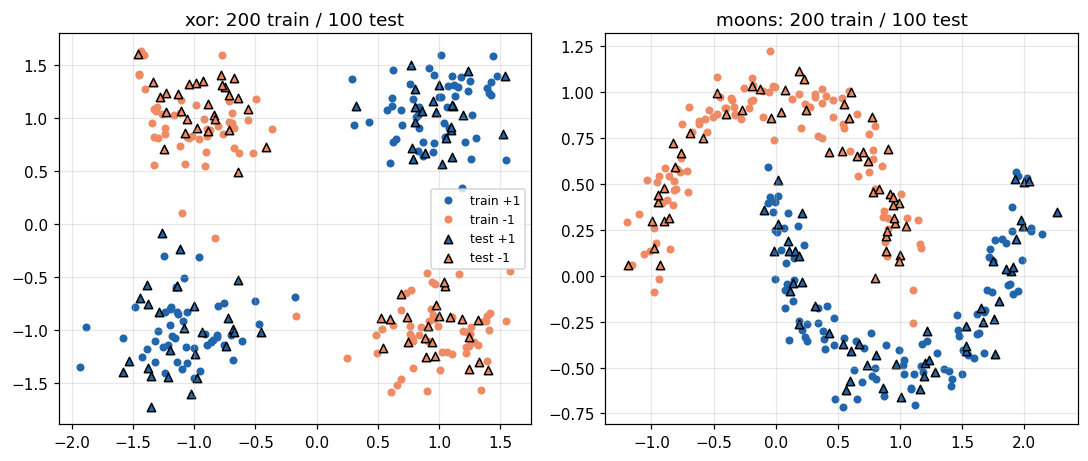

In [9]:
SIZES, BETA = [2, 5, 5, 5, 1], 0.5
LAYER_SLICES, _layer_of, _i = [], [], 0
for _l, (_n_in, _n_out) in enumerate(zip(SIZES[:-1], SIZES[1:])):
    LAYER_SLICES.append((_i, _i + _n_out * _n_in, _i + _n_out * _n_in + _n_out, _n_in, _n_out))
    _layer_of += [_l] * (_n_out * _n_in + _n_out)
    _i += _n_out * _n_in + _n_out
N_PARAMS = _i
LAYER_OF_NET = torch.tensor(_layer_of, device=DEVICE)
print(f"Network {SIZES}: {N_PARAMS} parameters, per layer: {torch.bincount(LAYER_OF_NET).tolist()}")


def make_xor(n, seed, std=0.3):
    rng = np.random.default_rng(seed)
    centres = np.array([[1, 1], [-1, -1], [-1, 1], [1, -1]], dtype=float)
    k = n // 4
    x = np.concatenate([c + std * rng.standard_normal((k, 2)) for c in centres])
    return x, np.array([1] * (2 * k) + [0] * (2 * k))


def load_task(name, seed=0):
    x, y = make_xor(300, seed) if name == "xor" else make_moons(300, noise=0.1, random_state=seed)
    x_tr, x_te, y_tr, y_te = train_test_split(x, y, test_size=100, stratify=y, random_state=seed)
    to_x = lambda a: torch.tensor(a, dtype=torch.float32, device=DEVICE)
    to_y = lambda a: torch.tensor(np.where(a == 1, 1.0, -1.0)[:, None], dtype=torch.float32, device=DEVICE)
    return dict(x_tr=to_x(x_tr), y_tr=to_y(y_tr), x_te=to_x(x_te), y_te=to_y(y_te), raw=(x_tr, y_tr, x_te, y_te))


TASKS = {"xor": load_task("xor"), "moons": load_task("moons")}


def forward(x, theta):
    """x: (n, 2) or (B, n, 2); theta: (B, 81) -> outputs (B, n, 1). tanh(beta * z) on every layer."""
    B, a = theta.shape[0], x
    for w0, w1, b1, n_in, n_out in LAYER_SLICES:
        W = theta[:, w0:w1].reshape(B, n_out, n_in)
        b = theta[:, w1:b1].reshape(B, 1, n_out)
        a = torch.tanh(BETA * (a @ W.transpose(1, 2) + b))
    return a


def sse(x, y, theta):
    """Paper Eq. 9, one value per network."""
    return ((forward(x, theta) - y) ** 2).sum(dim=(1, 2))


def accuracy(x, y, theta):
    return (forward(x, theta).sign() == y).float().mean(dim=(1, 2)) * 100


def init_networks(n, seed):
    g = torch.Generator().manual_seed(seed)
    return torch.randn(n, N_PARAMS, generator=g).to(DEVICE)


fig, axes = plt.subplots(1, 2, figsize=(10, 4.3))
for ax, (name, d) in zip(axes, TASKS.items()):
    x_tr, y_tr, x_te, y_te = d["raw"]
    ax.scatter(*x_tr[y_tr == 1].T, c="#2166ac", s=18, label="train +1")
    ax.scatter(*x_tr[y_tr == 0].T, c="#ef8a62", s=18, label="train -1")
    ax.scatter(*x_te[y_te == 1].T, c="#2166ac", marker="^", edgecolor="black", s=30, label="test +1")
    ax.scatter(*x_te[y_te == 0].T, c="#ef8a62", marker="^", edgecolor="black", s=30, label="test -1")
    ax.set_title(f"{name}: 200 train / 100 test")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

In [10]:
def sgd_train(task, theta0, lrs, epochs, batch_size, seed, epoch_callback=None, snapshot_epochs=()):
    """Mini-batch SGD with torch.optim.SGD on Eq. 9 (summed over the mini-batch).
    One parameter group per learning rate; every network gets its own shuffling each epoch.
    The full training loss is logged after every step."""
    x, y = task["x_tr"], task["y_tr"]
    gen = torch.Generator(device=DEVICE).manual_seed(seed)
    groups = [theta0.clone().requires_grad_(True) for _ in lrs]
    opt = torch.optim.SGD([{"params": [p], "lr": lr} for p, lr in zip(groups, lrs)], lr=lrs[0])
    n, B = x.shape[0], theta0.shape[0] * len(lrs)
    with torch.no_grad():
        theta = torch.cat(groups)
        loss_log, eval_log = [sse(x, y, theta)], [0.0]
        epoch_metrics = [epoch_callback(theta)] if epoch_callback else []
    snapshots = {}
    for epoch in range(1, epochs + 1):
        perm = torch.argsort(torch.rand(B, n, generator=gen, device=DEVICE), dim=1)
        for start in range(0, n, batch_size):
            idx = perm[:, start:start + batch_size]
            opt.zero_grad()
            sse(x[idx], y[idx], torch.cat(groups)).sum().backward()
            opt.step()
            with torch.no_grad():
                loss_log.append(sse(x, y, torch.cat(groups)))
            eval_log.append(eval_log[-1] + 3.0 * idx.shape[1] / n)
        with torch.no_grad():
            theta = torch.cat(groups)
            if epoch_callback:
                epoch_metrics.append(epoch_callback(theta))
            if epoch in snapshot_epochs:
                snapshots[epoch] = theta.clone()
    return theta.detach(), {"loss": torch.stack(loss_log).cpu(), "evals": np.array(eval_log),
                            "updates_per_epoch": -(-n // batch_size), "epoch_metrics": epoch_metrics,
                            "snapshots": snapshots}


def metrics_callback(task):
    def cb(theta):
        return dict(train_acc=accuracy(task["x_tr"], task["y_tr"], theta).cpu(),
                    test_acc=accuracy(task["x_te"], task["y_te"], theta).cpu())
    return cb


def test_metrics(task, theta):
    """Per-network test accuracy, precision, recall and F1 (positive class = +1), plus the summed confusion matrix."""
    out = torch.nan_to_num(forward(task["x_te"], theta), nan=1.0).squeeze(-1).cpu().numpy()
    pred = np.where(out >= 0, 1, -1)
    true = task["y_te"].squeeze(-1).cpu().numpy().astype(int)
    m = np.array([(accuracy_score(true, p), precision_score(true, p, zero_division=0),
                   recall_score(true, p, zero_division=0), f1_score(true, p, zero_division=0)) for p in pred]) * 100
    cm = sum(confusion_matrix(true, p, labels=[-1, 1]) for p in pred)
    return m, cm

### 5.2 Choosing $a$, $c$ and the SGD learning rate

The paper does not report $a$, $c$ or $t_{\max}$ for Fig. 1. We fix $t_{\max} = 50$ (the value it reports for MNIST) and 25 epochs (the length of Fig. 1d/1e), and choose the rest by sweep. Tuning uses 20 separate initial networks; the final results use 100 others.

- **SPSA:** $a \in \{0.002, 0.005, 0.01, 0.02, 0.05\}$, $c \in \{0.05, 0.1, 0.2\}$, for bottom-up layer-wise and for holistic SPSA. Following the paper, the **shared gains** are the best layer-wise setting, and all SPSA variants use them. The best holistic setting is also kept as an extra comparison.
- **SGD (`torch.optim.SGD`, batch 25):** learning rate in $\{0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5\}$, trained for 300 epochs. At 3 dataset passes per epoch, this is still about 10× fewer passes than SPSA's 25 epochs.
- **Selection criterion** (the paper's metric): the lowest mean final training error.

In [11]:
T_MAX, EPOCHS, SGD_EPOCHS, BATCH = 50, 25, 300, 25
A_NET, C_NET = [0.002, 0.005, 0.01, 0.02, 0.05], [0.05, 0.1, 0.2]
LR_NET = [0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5]
N_TUNE = 20
CHOSEN = {}

t_sweep = time.perf_counter()
for task_name, task in TASKS.items():
    theta_tune = init_networks(N_TUNE, seed=1000)
    configs = [(a, c) for a in A_NET for c in C_NET]
    a_vec = torch.tensor([a for a, c in configs for _ in range(N_TUNE)], device=DEVICE)
    c_vec = torch.tensor([c for a, c in configs for _ in range(N_TUNE)], device=DEVICE)
    f_train = lambda th, task=task: sse(task["x_tr"], task["y_tr"], th)
    res = {}
    for order in ("bottom-up", "holistic"):
        _, log = spsa_minimise(f_train, theta_tune.repeat(len(configs), 1), LAYER_OF_NET, order,
                               a_vec, c_vec, T_MAX, EPOCHS, TUNE_SEED)
        res[order] = log["loss"][-1].view(len(configs), N_TUNE)
    k_lw = min(range(len(configs)), key=lambda k: finite_mean(res["bottom-up"][k]))
    k_hol = min(range(len(configs)), key=lambda k: finite_mean(res["holistic"][k]))
    rows = [(a, c, f"{res['bottom-up'][k].mean():.2f}", f"{res['holistic'][k].mean():.2f}",
             ("<- shared gains" if k == k_lw else "") + (" <- best holistic" if k == k_hol else ""))
            for k, (a, c) in enumerate(configs)]
    print_table(f"[{task_name}] SPSA sweep: mean training error E after {EPOCHS} epochs ({N_TUNE} tuning networks)",
                ["a", "c", "layer-wise (bottom-up)", "holistic", ""], rows)

    th, log = sgd_train(task, theta_tune, LR_NET, SGD_EPOCHS, BATCH, TUNE_SEED)
    fin = log["loss"][-1].view(len(LR_NET), N_TUNE)
    at25 = log["loss"][EPOCHS * log["updates_per_epoch"]].view(len(LR_NET), N_TUNE)
    k_lr = min(range(len(LR_NET)), key=lambda k: finite_mean(fin[k]))
    print_table(f"[{task_name}] SGD learning-rate sweep ({N_TUNE} tuning networks, batch {BATCH})",
                ["lr", f"mean E after {EPOCHS} epochs", f"mean E after {SGD_EPOCHS} epochs", ""],
                [(lr, f"{at25[k].mean():.2f}", f"{fin[k].mean():.2f}", "<- chosen" if k == k_lr else "")
                 for k, lr in enumerate(LR_NET)])
    CHOSEN[task_name] = dict(shared=configs[k_lw], holistic_own=configs[k_hol], lr=LR_NET[k_lr])
    print(f"[{task_name}] chosen: shared (a, c) = {configs[k_lw]}, holistic own (a, c) = {configs[k_hol]}, "
          f"SGD lr = {LR_NET[k_lr]}\n")
print(f"Sweep time: {time.perf_counter() - t_sweep:.0f} s")

[xor] SPSA sweep: mean training error E after 25 epochs (20 tuning networks)
a     | c    | layer-wise (bottom-up) | holistic |                  
------+------+------------------------+----------+------------------
0.002 | 0.05 | 12.37                  | 3.70     |                  
0.002 | 0.1  | 10.53                  | 4.01     |                  
0.002 | 0.2  | 11.29                  | 4.33     |                  
0.005 | 0.05 | 5.17                   | 2.09     |                  
0.005 | 0.1  | 5.02                   | 1.88     |  <- best holistic
0.005 | 0.2  | 4.83                   | 2.76     |                  
0.01  | 0.05 | 22.78                  | 32.32    |                  
0.01  | 0.1  | 3.46                   | 60.12    | <- shared gains  
0.01  | 0.2  | 3.46                   | 12.47    |                  
0.02  | 0.05 | 83.63                  | 141.08   |                  
0.02  | 0.1  | 41.90                  | 66.99    |                  
0.02  | 0.2  | 7.29       

[xor] SGD learning-rate sweep (20 tuning networks, batch 25)
lr    | mean E after 25 epochs | mean E after 300 epochs |          
------+------------------------+-------------------------+----------
0.005 | 37.36                  | 3.28                    |          
0.01  | 9.42                   | 2.52                    |          
0.02  | 6.60                   | 1.71                    |          
0.05  | 5.52                   | 0.79                    | <- chosen
0.1   | 5.71                   | 0.98                    |          
0.2   | 161.18                 | 92.44                   |          
0.5   | 349.14                 | 347.08                  |          

[xor] chosen: shared (a, c) = (0.01, 0.1), holistic own (a, c) = (0.005, 0.1), SGD lr = 0.05



[moons] SPSA sweep: mean training error E after 25 epochs (20 tuning networks)
a     | c    | layer-wise (bottom-up) | holistic |                  
------+------+------------------------+----------+------------------
0.002 | 0.05 | 56.27                  | 13.51    |                  
0.002 | 0.1  | 56.61                  | 13.33    |                  
0.002 | 0.2  | 57.87                  | 21.93    |                  
0.005 | 0.05 | 29.22                  | 9.11     |                  
0.005 | 0.1  | 33.32                  | 15.76    |                  
0.005 | 0.2  | 28.01                  | 6.90     |  <- best holistic
0.01  | 0.05 | 33.61                  | 55.99    |                  
0.01  | 0.1  | 11.10                  | 115.64   | <- shared gains  
0.01  | 0.2  | 14.79                  | 42.75    |                  
0.02  | 0.05 | 17.49                  | 200.00   |                  
0.02  | 0.1  | 40.03                  | 179.70   |                  
0.02  | 0.2  | 28.33    

[moons] SGD learning-rate sweep (20 tuning networks, batch 25)
lr    | mean E after 25 epochs | mean E after 300 epochs |          
------+------------------------+-------------------------+----------
0.005 | 63.49                  | 10.55                   |          
0.01  | 57.88                  | 4.39                    |          
0.02  | 47.66                  | 0.20                    |          
0.05  | 34.61                  | 0.02                    |          
0.1   | 46.53                  | 0.01                    | <- chosen
0.2   | 184.67                 | 126.18                  |          
0.5   | 370.00                 | 352.00                  |          

[moons] chosen: shared (a, c) = (0.01, 0.1), holistic own (a, c) = (0.005, 0.2), SGD lr = 0.1

Sweep time: 123 s


### 5.3 Final runs: 100 initial networks × 6 methods × 2 tasks

| Method | Gains / learning rate | Paper |
|---|---|---|
| Layer-wise SPSA, bottom-up | shared $(a, c)$ | Algorithm 2, $\mathcal{L}_{bu}$ |
| Layer-wise SPSA, top-down | shared $(a, c)$ | Algorithm 2, $\mathcal{L}_{td}$ |
| Layer-wise SPSA, random order | shared $(a, c)$ | Algorithm 2, $\mathcal{L}_{rnd}$ |
| Holistic SPSA | shared $(a, c)$ | Fig. 1 "holistic" |
| Holistic SPSA | its own best $(a, c)$ | extra check (not in the paper) |
| SGD | `torch.optim.SGD`, chosen lr, batch 25, 300 epochs | course requirement |

In [12]:
RESULTS = {}
t_all = time.perf_counter()
for task_name, task in TASKS.items():
    theta0 = init_networks(N_TRIALS, seed=FINAL_SEED)
    f_train = lambda th, task=task: sse(task["x_tr"], task["y_tr"], th)
    ch = CHOSEN[task_name]
    plan = [("Layer-wise SPSA (bottom-up)", "bottom-up", ch["shared"]),
            ("Layer-wise SPSA (top-down)", "top-down", ch["shared"]),
            ("Layer-wise SPSA (random order)", "random", ch["shared"]),
            ("Holistic SPSA (same gains)", "holistic", ch["shared"]),
            ("Holistic SPSA (own best gains)", "holistic", ch["holistic_own"])]
    RESULTS[task_name] = {}
    for name, order, (a, c) in plan:
        sync(); t0 = time.perf_counter()
        th, log = spsa_minimise(f_train, theta0, LAYER_OF_NET, order, a, c, T_MAX, EPOCHS, FINAL_SEED,
                                epoch_callback=metrics_callback(task))
        sync()
        RESULTS[task_name][name] = dict(theta=th, log=log, setting=f"a={a}, c={c}", sec=time.perf_counter() - t0)
    sync(); t0 = time.perf_counter()
    th, log = sgd_train(task, theta0, [ch["lr"]], SGD_EPOCHS, BATCH, FINAL_SEED,
                        epoch_callback=metrics_callback(task), snapshot_epochs=(EPOCHS,))
    sync()
    RESULTS[task_name]["SGD (torch.optim.SGD)"] = dict(theta=th, log=log, setting=f"lr={ch['lr']}",
                                                       sec=time.perf_counter() - t0)
    print(f"[{task_name}] done")
print(f"All final runs: {time.perf_counter() - t_all:.0f} s")

[xor] done


[moons] done
All final runs: 219 s


### 5.4 Results tables

- **Training error $E$** (Eq. 9) is the paper's metric. "Success" means the final **training** accuracy is at least 95%; the paper notes that holistic SPSA *"converges only for a fraction of trials"*.
- **Accuracy, precision, recall and F1** are measured on the **held-out 100 test points**, as mean ± standard deviation over the 100 networks. Precision and recall treat $+1$ as the positive class.
- SGD is reported twice: after 25 epochs (the same number of epochs as SPSA) and after 300 epochs.

In [13]:
def per_epoch(log):
    return log["loss"][::log["updates_per_epoch"]]          # value after each epoch (index 0 = start)

def pm(v):
    return f"{np.mean(v):.1f} ± {np.std(v):.1f}"

SUMMARY = {}
for task_name, task in TASKS.items():
    rows = []
    SUMMARY[task_name] = {}
    entries = [(n, r["theta"], r["log"], EPOCHS, r) for n, r in RESULTS[task_name].items() if "SGD" not in n]
    sg = RESULTS[task_name]["SGD (torch.optim.SGD)"]
    entries.append((f"SGD @ {EPOCHS} epochs", sg["log"]["snapshots"][EPOCHS], sg["log"], EPOCHS, sg))
    entries.append((f"SGD @ {SGD_EPOCHS} epochs", sg["theta"], sg["log"], SGD_EPOCHS, sg))
    for name, theta, log, ep, r in entries:
        E = per_epoch(log)[ep].numpy()
        passes = log["evals"][ep * log["updates_per_epoch"]]
        train_acc = log["epoch_metrics"][ep]["train_acc"].numpy()
        m, cm = test_metrics(task, theta)
        SUMMARY[task_name][name] = dict(E=E, train_acc=train_acc, m=m, cm=cm, passes=passes)
        rows.append((name, r["setting"], f"{passes:.0f}", f"{E.mean():.2f}", f"{np.median(E):.2f}",
                     f"{100 * (train_acc >= 95).mean():.0f}%", pm(m[:, 0]), pm(m[:, 1]), pm(m[:, 2]), pm(m[:, 3])))
    print_table(f"[{task_name}] 100 networks each. E = training error (Eq. 9); test metrics in %, mean ± std",
                ["method", "setting", "dataset passes", "mean E", "median E", "success", "test acc",
                 "precision", "recall", "F1"], rows)

    ck = [0, 1, 2, 5, 10, 15, 20, 25]
    names = list(RESULTS[task_name])
    print_table(f"[{task_name}] mean training error E after each epoch (logged after the epoch's updates)",
                ["epoch"] + names,
                [[e] + [f"{per_epoch(RESULTS[task_name][n]['log'])[e].mean():.2f}" for n in names] for e in ck])

[xor] 100 networks each. E = training error (Eq. 9); test metrics in %, mean ± std
method                         | setting        | dataset passes | mean E | median E | success | test acc    | precision   | recall      | F1         
-------------------------------+----------------+----------------+--------+----------+---------+-------------+-------------+-------------+------------
Layer-wise SPSA (bottom-up)    | a=0.01, c=0.1  | 10000          | 3.03   | 3.02     | 100%    | 99.3 ± 0.5  | 100.0 ± 0.0 | 98.7 ± 0.9  | 99.3 ± 0.5 
Layer-wise SPSA (top-down)     | a=0.01, c=0.1  | 10000          | 5.00   | 2.85     | 99%     | 99.0 ± 2.3  | 99.7 ± 3.1  | 98.5 ± 0.8  | 99.0 ± 1.9 
Layer-wise SPSA (random order) | a=0.01, c=0.1  | 10000          | 4.94   | 2.88     | 99%     | 99.1 ± 2.4  | 100.0 ± 0.0 | 98.2 ± 4.7  | 99.0 ± 3.1 
Holistic SPSA (same gains)     | a=0.01, c=0.1  | 10000          | 50.75  | 3.93     | 76%     | 93.0 ± 11.7 | 95.3 ± 12.2 | 93.4 ± 15.9 | 92.8 ± 12.2
Holistic SP

[moons] 100 networks each. E = training error (Eq. 9); test metrics in %, mean ± std
method                         | setting        | dataset passes | mean E | median E | success | test acc    | precision   | recall      | F1         
-------------------------------+----------------+----------------+--------+----------+---------+-------------+-------------+-------------+------------
Layer-wise SPSA (bottom-up)    | a=0.01, c=0.1  | 10000          | 20.41  | 6.48     | 82%     | 96.0 ± 7.5  | 94.8 ± 9.6  | 98.7 ± 2.6  | 96.5 ± 6.3 
Layer-wise SPSA (top-down)     | a=0.01, c=0.1  | 10000          | 25.70  | 5.89     | 75%     | 95.4 ± 8.8  | 93.9 ± 13.0 | 97.0 ± 10.7 | 95.2 ± 11.5
Layer-wise SPSA (random order) | a=0.01, c=0.1  | 10000          | 24.55  | 6.15     | 81%     | 95.6 ± 8.9  | 94.0 ± 13.3 | 97.4 ± 10.2 | 95.5 ± 11.4
Holistic SPSA (same gains)     | a=0.01, c=0.1  | 10000          | 74.27  | 11.86    | 60%     | 88.7 ± 16.1 | 84.9 ± 26.7 | 88.9 ± 25.9 | 86.1 ± 25.5
Holistic 

### 5.5 Loss curves (the paper's Fig. 1d/1e style), loss vs. evaluations, and test accuracy

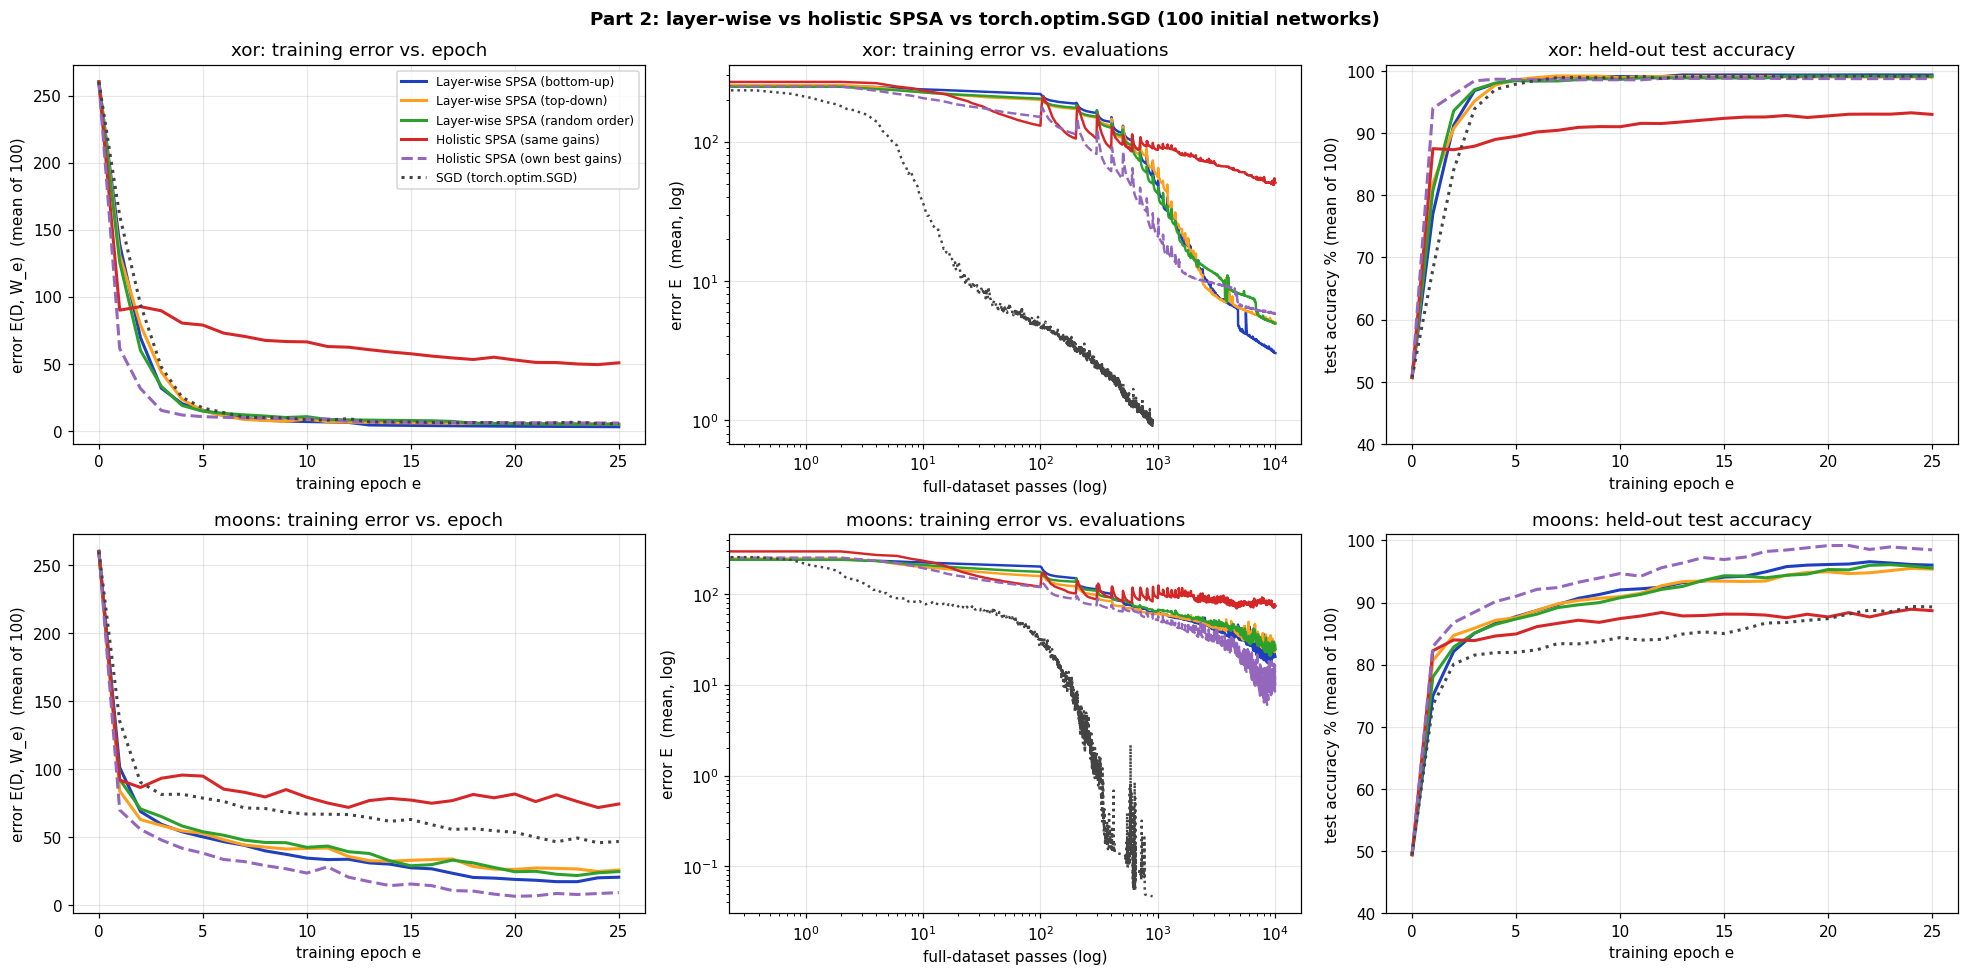

In [14]:
STYLE = {"Layer-wise SPSA (bottom-up)": ("#1f3fbf", "-"), "Layer-wise SPSA (top-down)": ("#ff9f1c", "-"),
         "Layer-wise SPSA (random order)": ("#2ca02c", "-"), "Holistic SPSA (same gains)": ("#d62728", "-"),
         "Holistic SPSA (own best gains)": ("#9467bd", "--"), "SGD (torch.optim.SGD)": ("#444444", ":")}

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for row, task_name in enumerate(TASKS):
    for name, r in RESULTS[task_name].items():
        color, ls = STYLE[name]
        log = r["log"]
        E = per_epoch(log)
        axes[row, 0].plot(np.arange(EPOCHS + 1), E[:EPOCHS + 1].mean(dim=1), color=color, ls=ls, lw=2, label=name)
        axes[row, 1].plot(log["evals"], log["loss"].mean(dim=1), color=color, ls=ls, lw=1.6, label=name)
        acc = torch.stack([m["test_acc"] for m in log["epoch_metrics"][:EPOCHS + 1]]).mean(dim=1)
        axes[row, 2].plot(np.arange(EPOCHS + 1), acc, color=color, ls=ls, lw=2, label=name)
    axes[row, 0].set(xlabel="training epoch e", ylabel="error E(D, W_e)  (mean of 100)",
                     title=f"{task_name}: training error vs. epoch")
    axes[row, 1].set(xscale="log", yscale="log", xlabel="full-dataset passes (log)", ylabel="error E  (mean, log)",
                     title=f"{task_name}: training error vs. evaluations")
    axes[row, 2].set(xlabel="training epoch e", ylabel="test accuracy % (mean of 100)", ylim=(40, 101),
                     title=f"{task_name}: held-out test accuracy")
axes[0, 0].legend(fontsize=8)
fig.suptitle("Part 2: layer-wise vs holistic SPSA vs torch.optim.SGD (100 initial networks)", fontweight="bold")
plt.tight_layout()
plt.show()

### 5.6 Confusion matrices and decision boundaries

- **Confusion matrices** are summed over all 100 trained networks: 100 networks × 100 test points = 10,000 predictions per matrix. Each row is normalised by its true class.
- **Decision boundaries** are shown for trial 0, the first initial network. It is not hand-picked.

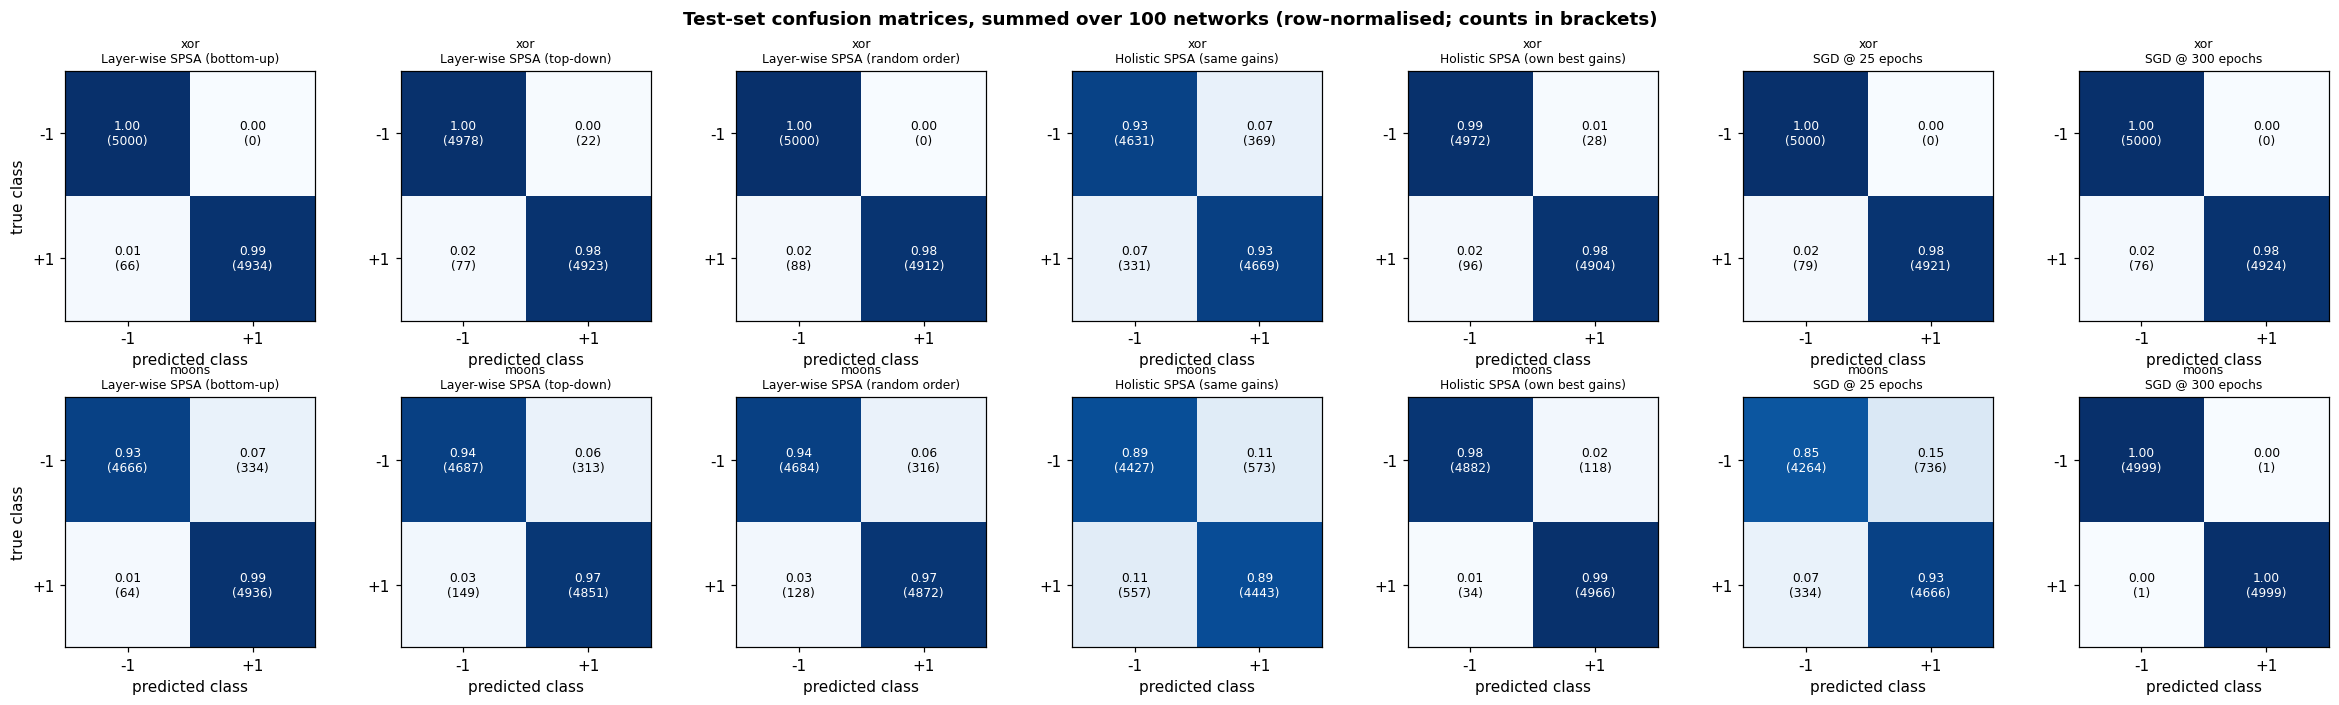

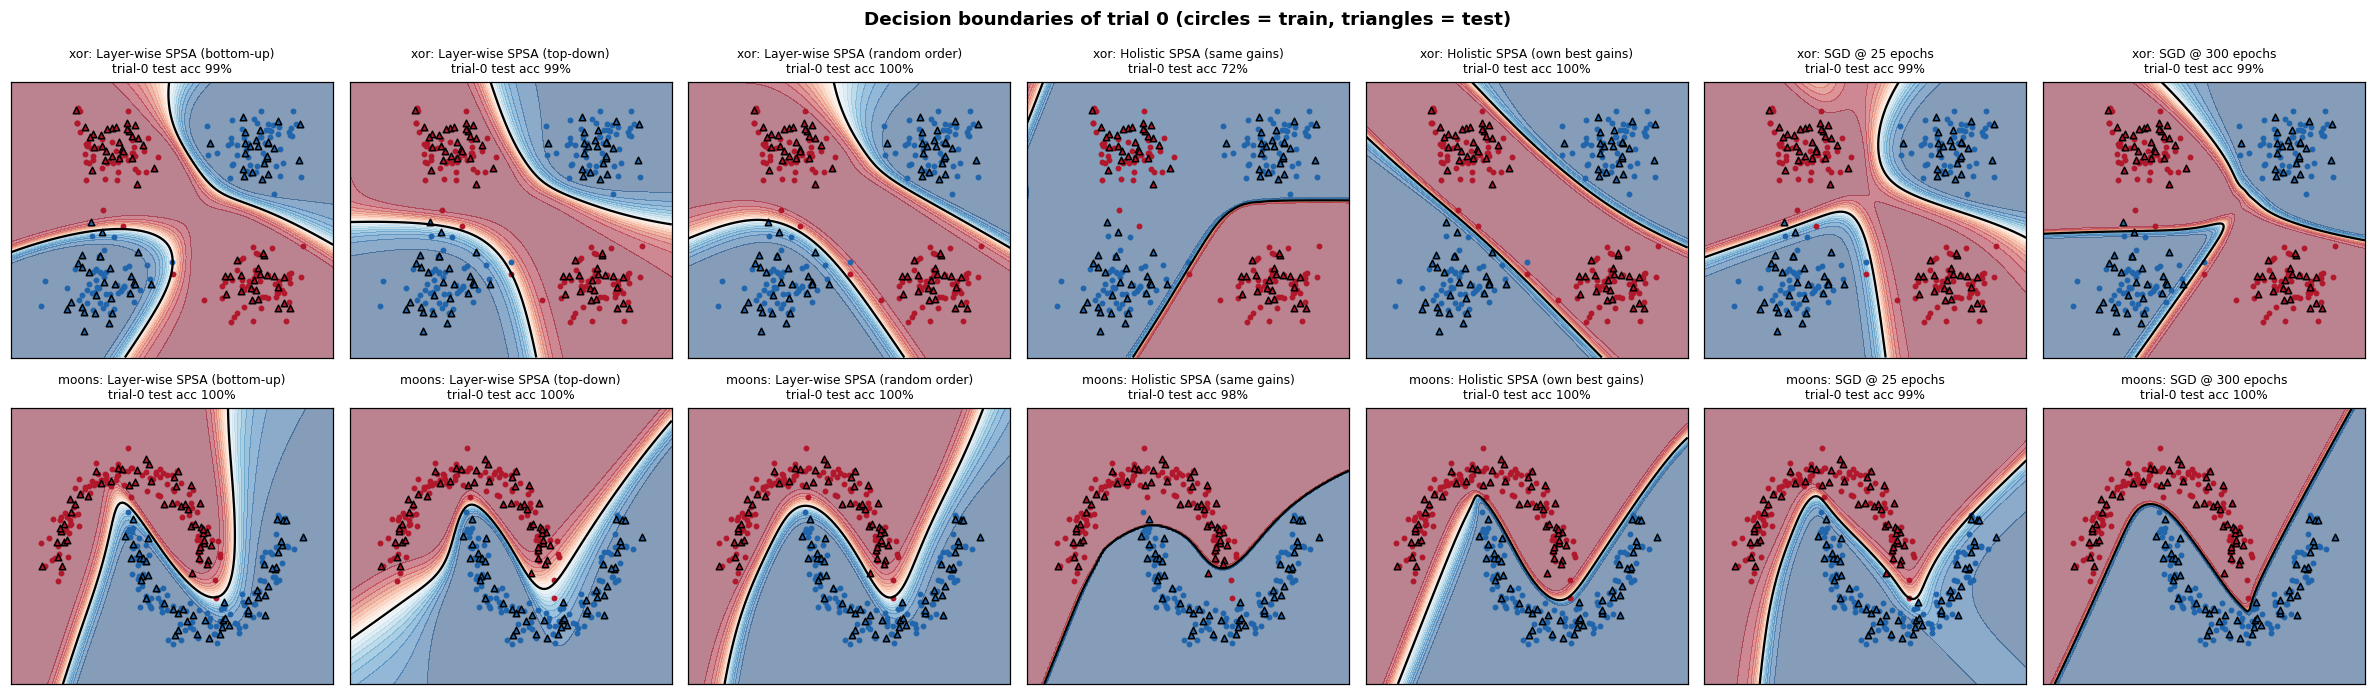

In [15]:
show = list(RESULTS["xor"].keys())[:-1] + [f"SGD @ {EPOCHS} epochs", f"SGD @ {SGD_EPOCHS} epochs"]
fig, axes = plt.subplots(2, len(show), figsize=(3.1 * len(show), 6.4))
for row, task_name in enumerate(TASKS):
    for col, name in enumerate(show):
        cm = SUMMARY[task_name][name]["cm"]
        cmn = cm / cm.sum(axis=1, keepdims=True)
        ax = axes[row, col]
        ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{cmn[i, j]:.2f}\n({cm[i, j]})", ha="center", va="center",
                        color="white" if cmn[i, j] > 0.6 else "black", fontsize=8)
        ax.set_xticks([0, 1], ["-1", "+1"]); ax.set_yticks([0, 1], ["-1", "+1"])
        ax.grid(False)
        ax.set_title(f"{task_name}\n{name}", fontsize=8)
        if col == 0:
            ax.set_ylabel("true class")
        ax.set_xlabel("predicted class")
fig.suptitle("Test-set confusion matrices, summed over 100 networks (row-normalised; counts in brackets)", fontweight="bold")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, len(show), figsize=(3.1 * len(show), 6.4))
for row, (task_name, task) in enumerate(TASKS.items()):
    x_tr, y_tr, x_te, y_te = task["raw"]
    allx = np.concatenate([x_tr, x_te])
    lo, hi = allx.min(axis=0) - 0.4, allx.max(axis=0) + 0.4
    gx, gy = np.meshgrid(np.linspace(lo[0], hi[0], 160), np.linspace(lo[1], hi[1], 160))
    grid = torch.tensor(np.c_[gx.ravel(), gy.ravel()], dtype=torch.float32, device=DEVICE)
    for col, name in enumerate(show):
        if name.startswith("SGD @"):
            sg = RESULTS[task_name]["SGD (torch.optim.SGD)"]
            theta = sg["log"]["snapshots"][EPOCHS] if name.endswith(f"{EPOCHS} epochs") else sg["theta"]
        else:
            theta = RESULTS[task_name][name]["theta"]
        z = forward(grid, theta[:1]).reshape(gx.shape).cpu().numpy()
        ax = axes[row, col]
        ax.contourf(gx, gy, z, levels=np.linspace(-1, 1, 21), cmap="RdBu", alpha=0.5)
        ax.contour(gx, gy, z, levels=[0], colors="black", linewidths=1.5)
        ax.scatter(*x_tr[y_tr == 1].T, c="#2166ac", s=8)
        ax.scatter(*x_tr[y_tr == 0].T, c="#b2182b", s=8)
        ax.scatter(*x_te[y_te == 1].T, c="#2166ac", marker="^", edgecolor="black", s=18)
        ax.scatter(*x_te[y_te == 0].T, c="#b2182b", marker="^", edgecolor="black", s=18)
        acc = SUMMARY[task_name][name]["m"][0, 0]
        ax.set_title(f"{task_name}: {name}\ntrial-0 test acc {acc:.0f}%", fontsize=8)
        ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Decision boundaries of trial 0 (circles = train, triangles = test)", fontweight="bold")
plt.tight_layout()
plt.show()

In [16]:
# Numbers used in the takeaways below, printed from this run
for task_name in TASKS:
    S = SUMMARY[task_name]
    print(f"[{task_name}] chosen: {CHOSEN[task_name]}")
    for name, s in S.items():
        print(f"   {name:32s} mean E {s['E'].mean():7.2f} | success {100 * (s['train_acc'] >= 95).mean():3.0f}% | "
              f"test acc {s['m'][:, 0].mean():5.1f} | precision {s['m'][:, 1].mean():5.1f} | recall {s['m'][:, 2].mean():5.1f} "
              f"| F1 {s['m'][:, 3].mean():5.1f} | dataset passes {s['passes']:.0f}")

[xor] chosen: {'shared': (0.01, 0.1), 'holistic_own': (0.005, 0.1), 'lr': 0.05}
   Layer-wise SPSA (bottom-up)      mean E    3.03 | success 100% | test acc  99.3 | precision 100.0 | recall  98.7 | F1  99.3 | dataset passes 10000
   Layer-wise SPSA (top-down)       mean E    5.00 | success  99% | test acc  99.0 | precision  99.7 | recall  98.5 | F1  99.0 | dataset passes 10000
   Layer-wise SPSA (random order)   mean E    4.94 | success  99% | test acc  99.1 | precision 100.0 | recall  98.2 | F1  99.0 | dataset passes 10000
   Holistic SPSA (same gains)       mean E   50.75 | success  76% | test acc  93.0 | precision  95.3 | recall  93.4 | F1  92.8 | dataset passes 10000
   Holistic SPSA (own best gains)   mean E    5.80 | success  98% | test acc  98.8 | precision  99.6 | recall  98.1 | F1  98.7 | dataset passes 10000
   SGD @ 25 epochs                  mean E    5.28 | success 100% | test acc  99.2 | precision 100.0 | recall  98.4 | F1  99.2 | dataset passes 75
   SGD @ 300 epochs    

## 6. Takeaways

All numbers below come from the run above: 100 trials each, on the GPU.

### Part 1A: SPSA on $f(x, y) = x^3 + y^3 - 3xy + 1$
- **SPSA (Algorithm 1) converges to the local minimum $(1, 1)$ in all 100 trials.** Using the selected gains ($t_{\max} = 5$, $a = 0.05$, $c = 0.02$):
  - the median $f$ falls from 7.227 to $1.4 \times 10^{-2}$ after 15 iterations, $1.3 \times 10^{-5}$ after 60, and $3.7 \times 10^{-8}$ after 150;
  - 150 iterations cost **300 function evaluations**.
- **SGD (`torch.optim.SGD`, lr 0.01) also reaches $(1, 1)$ in all 100 trials, but levels off near $f \approx 10^{-5}$.** With a constant learning rate, the gradient noise ($\sigma = 0.05$) sets a floor. That floor comes from the noise level we chose, not from SGD itself; SPSA here sees exact function values.
- **The gain restarts matter.** With one long call ($t_{\max} = 50$, i.e. $a_t = a/t$ without restarts), at most 82% of the trials converge (sweep table). Restarting $a_t$ and $c_t$ every $t_{\max}$ steps is the paper's own schedule (Sect. 5).

### Part 1B: layer-wise vs. holistic SPSA on a 3-layer matrix product (75 parameters)
- **With the same gains** ($a = 0.03$, $c = 0.1$), **layer-wise SPSA converges in all 100 trials** (median $f = 9.1 \times 10^{-5}$), while **holistic SPSA diverges in all 100**. In the sweep, holistic SPSA starts to diverge from $a = 0.02$; layer-wise never diverges on the grid.
- **This matches the paper's argument** that perturbing one layer at a time gives better gradient estimates: here it shows up as tolerating roughly 3× larger steps.
- **With its own best gains** ($a = 0.01$, $c = 0.02$), holistic SPSA converges too, but ends about 2× worse (median $1.9 \times 10^{-4}$).
- **SGD with exact gradients plus noise** reaches $8.1 \times 10^{-5}$ for the same budget. Gradient information is worth a lot when it is available.

### Part 2: the paper's 81-parameter network on XOR and moons (Fig. 1a/1b, 1d/1e)
**Layer-wise beats holistic SPSA, as the paper reports.** The paper: *"alternating or layer-wise SPSA according to Algorithm 2 learns better than a holistic variant where all weights are updated simultaneously. Using the holistic approach, learning converges only for a fraction of trials."* With shared gains, after 25 epochs:

| Task | Measure | Layer-wise (bottom-up) | Holistic | Paper Fig. 1 (approx.) |
|---|---|---|---|---|
| XOR | mean training error $E$ | **3.03** | 50.75 | ≈ 5 vs. ≈ 90 (Fig. 1d) |
| XOR | trials ≥ 95% train accuracy | 100% | 76% | |
| Moons | mean training error $E$ | **20.41** | 74.27 | ≈ 10 vs. ≈ 85 (Fig. 1e) |
| Moons | trials ≥ 95% train accuracy | 82% | 60% | |

The paper's values are read off its plots, so they are approximate.

**The layer order hardly matters, as the paper reports.** The paper: *"whether updating layer $l$ is chosen from $\mathcal{L}_{td}$, $\mathcal{L}_{bu}$, or $\mathcal{L}_{rnd}$ does not seem to impact training errors."*

| Task | bottom-up | top-down | random |
|---|---|---|---|
| XOR, median $E$ | 3.02 | 2.85 | 2.88 |
| Moons, median $E$ | 6.48 | 5.89 | 6.15 |

The means differ a little more (XOR 3.0 / 5.0 / 4.9) because of a few slow trials.

**When holistic SPSA gets its own step size, the gap closes on this small network.** At $a = 0.005$, holistic SPSA reaches $E = 5.80$ on XOR (98% success) and $9.14$ on moons (93%). So at 81 parameters, layer-wise SPSA's advantage is mainly that it **tolerates larger steps**. The paper's curse-of-dimensionality argument is about much larger networks (its MNIST experiment, not reproduced here).

**On held-out test points**, layer-wise SPSA (bottom-up) gets:

| Task | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|
| XOR | 99.3% | 100.0% | 98.7% | 99.3% |
| Moons | 96.0% | 94.8% | 98.7% | 96.5% |

Holistic SPSA with shared gains reaches 93.0% (XOR) and 88.7% (moons), with much larger spread across trials. The confusion matrices show where the errors fall.

### SPSA vs. SGD: per epoch vs. per evaluation
**Per epoch:**

| Task | After 25 epochs | Layer-wise SPSA | SGD |
|---|---|---|---|
| XOR | mean $E$ | 3.03 | 5.28 |
| Moons | mean $E$ | 20.41 | 46.71 |
| Moons | test accuracy | 96.0% | 89.3% |

**But an SPSA epoch costs far more.** SPSA's 25 epochs use **10,000 dataset passes**; SGD's 25 epochs use **75**. Given only 900 passes (300 epochs), SGD reaches $E = 0.91$ (XOR) and $0.05$ (moons), with 99.2% and 100% test accuracy. The loss-vs-evaluations plot shows this: per unit of compute, backpropagation is far more efficient.

**The paper makes the same caveat** about its MNIST comparison with GD: *"during one epoch, extended Algorithm 2 contains additional iterations over weights and biases compared to GD. Furthermore, each application of SPSA (Algorithm 1) entails $t_{max}$ partial weight updates, while GD only contains one update of all parameters per batch. Anyway, we neither aim for a quantitative comparison between the two approaches nor for achieving state of the art results."* Its MNIST observation was: *"While GD achieves a higher accuracy after additional training epochs, SPSA already learns within the first twelve epochs."*

**What SPSA offers is training with forward passes only**: no gradients and no backward pass. That is the paper's stated goal, not speed.

### Scope and limits
- **Tasks and settings:**
  - The tasks are the paper's 2-class XOR and moons problems, regenerated, since the exact data was not published.
  - The earlier notebooks' 2-class circles demo is **not** the paper's Fig. 1c (a 3-class task with 503 parameters), and it is not used here.
  - Fig. 1c and the MNIST experiment (Fig. 2) are not reproduced.
- **Hyperparameters:** $a$, $c$ and the SGD learning rates come from the sweeps above, because the paper does not report them for Fig. 1. In Part 1B the best layer-wise $a$ is at the edge of the grid, so layer-wise SPSA might do slightly better with a larger $a$.
- **Reproducibility:** results are averaged over 100 trials. GPU arithmetic can change the last digits from run to run, but not the conclusions.